<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border-bottom:1px solid rgba(148,163,184,0.35);padding-bottom:12px;margin-bottom:14px;">
<h1 style="text-align:right;color:inherit;margin:5px 0;">هفتهٔ ۱۴ | Logistic Regression، Regularization، Ridge، Lasso و Tikhonov</h1>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">اهداف هفته</h3>
<p style="margin:6px 0;text-align:right;">ابتدا طبقه‌بندی دودویی و Logistic Regression را با یک مسئلهٔ صنعتی یاد می‌گیریم؛ سپس سراغ کنترل پیچیدگی با Regularization، Ridge، Lasso و Tikhonov می‌رویم. تمرین‌های From Scratch نیز در هر بخش قرار دارند.</p><ul><li>درک Linear Score، Sigmoid، Probability، Threshold و Decision Boundary</li><li>حل مسئلهٔ کاربردی پایش دستگاه صنعتی با دادهٔ شبیه‌سازی‌شده</li><li>آموزش Logistic Regression با Scikit-learn و تمرین از صفر با NumPy</li><li>شهود و ریاضیات Regularization، Ridge و Lasso</li><li>نمودارهای تابع جریمه و هندسهٔ L1/L2 و انتخاب Alpha</li><li>حل عددی Ridge/Lasso از صفر و کاهش نویز از سیگنال با Tikhonov</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">پیش‌نیازها و کتابخانه‌ها</h2><p>رگرسیون خطی/چندجمله‌ای، مشتق مقدماتی، MSE، تقسیم Train/Test، Pipeline و Cross Validation قبلاً تدریس شده‌اند. ترتیب این هفته: Logistic → Ridge → Lasso/Tikhonov.</p></div>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display

SEED = 42
np.random.seed(SEED)

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Environment is ready.")

NumPy version: 2.2.6
Pandas version: 2.3.2
Environment is ready.


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">جلسهٔ اول | از Regression به Logistic Regression</h2><p>زمان: ۷۵ دقیقه — معنی احتمالاتیِ خروجی، ساختار ریاضی، سپس کدنویسی.</p></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">شروع مفهومی جلسهٔ اول | خروجی پیوسته یا تصمیم دودویی؟</h3>

<p>وقتی قیمت خانه را پیش‌بینی می‌کنیم، پاسخ عدد پیوسته است. اما در یک سامانهٔ هشدار صنعتی می‌خواهیم بدانیم «دستگاه نیاز به بررسی دارد یا نه؟». قبل از گفتن نام الگوریتم، از کلاس بپرس: «آیا بهتر است فقط برچسب بدهیم یا میزان اطمینان/خطر را هم گزارش کنیم؟»</p>
<p>Logistic Regression برخلاف نامش، برای طبقه‌بندی دودویی استفاده می‌شود. ابتدا یک امتیاز خطی می‌سازد، بعد با Sigmoid آن را به عددی بین صفر و یک تبدیل می‌کند؛ آستانهٔ تصمیم در مرحلهٔ بعد اعمال می‌شود.</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">سؤال آغازین: چه وقت مقدار می‌خواهیم و چه وقت برچسب؟</h3>
<p style="margin:6px 0;text-align:right;">در رگرسیون مقدار عددی پیوسته پیش‌بینی می‌کنیم؛ در طبقه‌بندی یک برچسب از چند کلاس ممکن. برای مثال «قیمت خانه چقدر است؟» رگرسیون است؛ «ایمیل هرزنامه است یا نه؟» طبقه‌بندی دودویی است.</p>
<p style="margin:6px 0;text-align:right;">در Binary Classification، معمولاً دو برچسب ۰ و ۱ داریم. اینکه کدام معنا دارد باید از تعریف مسئله مشخص باشد؛ خود عدد ۱ لزوماً به معنای «خوب» یا «مثبت پزشکی» نیست.</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">چرا Linear Regression برای احتمال کلاس مناسب نیست؟</h3>
<p style="margin:6px 0;text-align:right;">مدل خطی با افزایش ویژگی بدون محدودیت بالا یا پایین می‌رود. اگر برچسب‌ها ۰/۱ باشند، هنوز ممکن است پیش‌بینی‌هایی مثل منفی ۰٫۲ یا ۱٫۱۵ بسازد؛ چنین عددهایی احتمال معتبر نیستند.</p>
<p style="margin:6px 0;text-align:right;">مشکل فقط بازهٔ خروجی نیست: مدل‌های طبقه‌بندی معمولاً تابع هزینه و مدل احتمالاتی متناسب با ماهیت برچسب‌ها دارند. این هفته ساختار خروجی را می‌فهمیم و هفتهٔ پانزدهم تابع هزینه را مشتق می‌کنیم.</p>
</div></div>

$$
\hat y_{\mathrm{linear}}=\mathbf w^T\mathbf x+b\quad\in\mathbb R
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">آزمایش: خروجی خطی روی کلاس ۰ و ۱</h3>
<p style="margin:6px 0;text-align:right;">دو گروه مصنوعی می‌سازیم و خط رگرسیون را روی برچسب‌ها می‌کشیم؛ از قبل پیش‌بینی کن آیا خط می‌تواند از بازهٔ [0,1] عبور کند.</p>
</div></div>

Minimum linear output: -0.286
Maximum linear output: 1.143


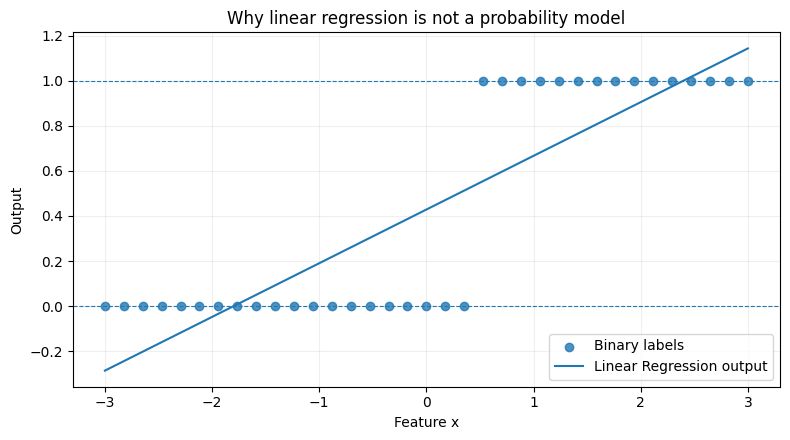

In [3]:
# A one-dimensional binary dataset: labels are 0 or 1.
x_binary = np.linspace(-3, 3, 35).reshape(-1, 1)
y_binary = (x_binary[:, 0] > 0.4).astype(int)

linear_for_classification = LinearRegression().fit(x_binary, y_binary)
linear_scores = linear_for_classification.predict(x_binary)

print("Minimum linear output:", round(float(linear_scores.min()), 3))
print("Maximum linear output:", round(float(linear_scores.max()), 3))

plt.figure(figsize=(8, 4.5))
plt.scatter(x_binary[:, 0], y_binary, label="Binary labels", alpha=0.8)
plt.plot(x_binary[:, 0], linear_scores, label="Linear Regression output")
plt.axhline(0, linestyle="--", linewidth=0.8)
plt.axhline(1, linestyle="--", linewidth=0.8)
plt.xlabel("Feature x")
plt.ylabel("Output")
plt.title("Why linear regression is not a probability model")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">از نمرهٔ خطی به احتمال: Logistic Regression</h3>
<p style="margin:6px 0;text-align:right;">ابتدا مانند رگرسیون خطی یک امتیاز z از جمع وزنی ویژگی‌ها تولید می‌کنیم. سپس با تابع Sigmoid آن را به عددی بین صفر و یک تبدیل می‌کنیم. به این عدد تخمین احتمال کلاس ۱ می‌گوییم.</p>
<p style="margin:6px 0;text-align:right;">نباید این جمله را با «مدل حتماً واقعیت را با احتمال درست می‌داند» اشتباه گرفت؛ کیفیت احتمال به آموزش، داده و Calibration بستگی دارد.</p>
</div></div>

$$
z=\mathbf w^T\mathbf x+b
$$

$$
\sigma(z)=\frac{1}{1+e^{-z}}\qquad 0<\sigma(z)<1
$$

$$
\hat p=P(y=1\mid \mathbf x)\approx\sigma(\mathbf w^T\mathbf x+b)
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">خواص مهم تابع Sigmoid</h3>
<p style="margin:6px 0;text-align:right;">برای z=۰ مقدار تابع ۰٫۵ است. برای z مثبت، احتمال از ۰٫۵ بیشتر؛ برای z منفی از ۰٫۵ کمتر است. تابع صعودی و S-شکل است، ولی در دو انتهای مثبت و منفی به صفر و یک نزدیک می‌شود و به آن‌ها دقیقاً نمی‌رسد.</p>
<p style="margin:6px 0;text-align:right;">مشتق آن برابر σ(z)(1−σ(z)) است. شیب در مرکز حداکثر است و به سمت اشباع کم می‌شود؛ این نکته بعدها برای شبکه‌های عصبی هم مفید است.</p>
</div></div>

$$
\sigma(0)=\frac12\qquad\qquad \sigma(-z)=1-\sigma(z)
$$

$$
\sigma\,\!\prime(z)=\sigma(z)\bigl(1-\sigma(z)\bigr)
$$

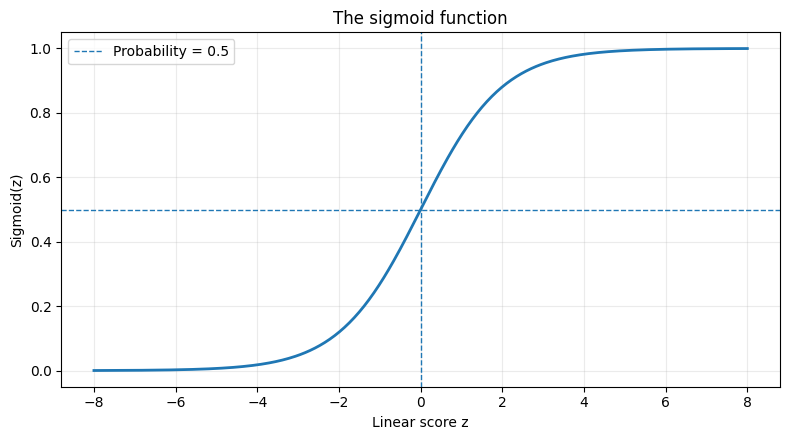

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_values = np.linspace(-8, 8, 400)
probabilities = sigmoid(z_values)

plt.figure(figsize=(8, 4.5))
plt.plot(z_values, probabilities, linewidth=2)
plt.axhline(0.5, linestyle="--", linewidth=1, label="Probability = 0.5")
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Linear score z")
plt.ylabel("Sigmoid(z)")
plt.title("The sigmoid function")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">Odds و Log-Odds: چرا نام Logistic معنا دارد؟</h3>
<p style="margin:6px 0;text-align:right;">اگر احتمال رخداد p باشد، Odds برابر نسبت شانس رخداد به عدم‌رخداد است. برای p=۰٫۸، Odds برابر ۴ می‌شود؛ یعنی شانس کلاس ۱ چهار برابر شانس کلاس ۰ است. Log-Odds لگاریتم همین نسبت است.</p>
<p style="margin:6px 0;text-align:right;">در Logistic Regression، Log-Odds برابر همان نمرهٔ خطی z می‌شود؛ بنابراین مدل در فضای لگاریتم نسبت شانس، خطی است. این نکته فرق میان «مدل خطیِ امتیاز» و «خروجی غیرخطی احتمال» را روشن می‌کند.</p>
</div></div>

$$
\mathrm{Odds}=\frac{p}{1-p}\qquad\mathrm{Logit}(p)=\log\left(\frac{p}{1-p}\right)
$$

$$
\log\left(\frac{p}{1-p}\right)=z=\mathbf w^T\mathbf x+b
$$

In [4]:
probability_examples = [0.2, 0.5, 0.8]

for probability in probability_examples:
    odds = probability / (1 - probability)
    log_odds = np.log(odds)
    print(
        f"p={probability:.1f} | odds={odds:.3f} | "
        f"log-odds={log_odds:.3f}"
    )

p=0.2 | odds=0.250 | log-odds=-1.386
p=0.5 | odds=1.000 | log-odds=0.000
p=0.8 | odds=4.000 | log-odds=1.386


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">Threshold و تبدیل Probability به Class Label</h3>
<p style="margin:6px 0;text-align:right;">احتمال یک عدد پیوسته است. برای اعلام نتیجهٔ «۰ یا ۱» باید یک قانون تصمیم داشته باشیم. Threshold معمولِ طبقه‌بندی دودویی ۰٫۵ است، اما در مسئله‌های واقعی می‌تواند بر حسب هزینهٔ خطا عوض شود.</p>
<p style="margin:6px 0;text-align:right;">تغییر Threshold لزوماً نیازمند آموزش دوبارهٔ پارامترها نیست؛ تنها برچسب نهایی بر پایهٔ همان احتمال‌ها تغییر می‌کند. افزایش Threshold معمولاً تعداد پیش‌بینی‌های کلاس ۱ را کم می‌کند.</p>
</div></div>

$$
\hat y=\begin{cases}1,&\hat p\ge t\\0,&\hat p<t\end{cases}\qquad (0<t<1)
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">Decision Boundary را از معادله استخراج کنیم</h3>
<p style="margin:6px 0;text-align:right;">مرز تصمیم مجموعهٔ نقاطی است که مدل در آن‌ها دقیقاً به Threshold انتخابی می‌رسد. چون Sigmoid صعودی است، می‌توان آن را وارونه کرد و به معادله‌ای در فضای z رسید.</p>
<p style="margin:6px 0;text-align:right;">برای t=۰٫۵، مرز در z=۰ قرار دارد؛ در دو ویژگی یک خط و در p ویژگی یک ابرصفحه است. برای t دلخواه، مقدار ثابتِ سمت راست عوض می‌شود؛ بنابراین خط یا ابرصفحه می‌تواند جابه‌جا شود، بدون آنکه w تغییر کند.</p>
</div></div>

$$
\sigma(\mathbf w^T\mathbf x+b)=t\iff\mathbf w^T\mathbf x+b=\log\left(\frac{t}{1-t}\right)
$$

$$
t=0.5\quad\Longrightarrow\quad \mathbf w^T\mathbf x+b=0
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">آزمایش نهایی: آموزش Logistic Regression با Scikit-learn</h3>
<p style="margin:6px 0;text-align:right;">ابتدا دیتاست دوبعدی می‌سازیم و به Train/Test تقسیم می‌کنیم. StandardScaler و LogisticRegression را در یک Pipeline قرار می‌دهیم. برای بررسی احتمال کلاس ۱، همیشه ترتیب کلاس‌ها را از classes_ می‌خوانیم.</p>
<p style="margin:6px 0;text-align:right;">یادآوری فنی: LogisticRegression در Scikit-learn به‌صورت پیش‌فرض Regularization هم دارد و پارامتر C شدت وارون آن را کنترل می‌کند. امروز تمرکزمان روی خروجی احتمالاتی و مرز تصمیم است، نه تنظیم C.</p>
</div></div>

In [5]:
X_classification, y_classification = make_classification(
    n_samples=400,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.5,
    flip_y=0.05,
    random_state=SEED
)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_classification,
    y_classification,
    test_size=0.25,
    random_state=SEED,
    stratify=y_classification
)

print("Training shape:", X_train_cls.shape)
print("Test shape:", X_test_cls.shape)
print("Training class counts:", np.bincount(y_train_cls))

Training shape: (300, 2)
Test shape: (100, 2)
Training class counts: [151 149]


In [6]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(random_state=SEED))
])

logistic_pipeline.fit(X_train_cls, y_train_cls)

predicted_labels = logistic_pipeline.predict(X_test_cls)
class_probabilities = logistic_pipeline.predict_proba(X_test_cls)
class_order = logistic_pipeline.named_steps["logistic"].classes_

print("Class order:", class_order)
print("First 10 predicted labels:", predicted_labels[:10])
print("First 10 probability rows:\n", np.round(class_probabilities[:10], 3))
print("Probability rows sum to 1:", np.allclose(class_probabilities.sum(axis=1), 1.0))

Class order: [0 1]
First 10 predicted labels: [0 0 0 0 1 1 0 0 0 1]
First 10 probability rows:
 [[0.997 0.003]
 [0.952 0.048]
 [0.915 0.085]
 [0.936 0.064]
 [0.067 0.933]
 [0.045 0.955]
 [0.702 0.298]
 [0.901 0.099]
 [0.932 0.068]
 [0.182 0.818]]
Probability rows sum to 1: True


In [7]:
positive_class_index = int(np.where(class_order == 1)[0][0])
positive_probabilities = class_probabilities[:, positive_class_index]

for threshold in [0.3, 0.5, 0.7]:
    threshold_predictions = (positive_probabilities >= threshold).astype(int)
    print(
        f"Threshold={threshold:.1f} | predicted class 1: "
        f"{np.sum(threshold_predictions == 1)} | "
        f"predicted class 0: {np.sum(threshold_predictions == 0)}"
    )

# At the default threshold 0.5, this should agree with LogisticRegression.predict.
predictions_at_half = (positive_probabilities >= 0.5).astype(int)
print("Matches predict() at threshold 0.5:", np.array_equal(predictions_at_half, predicted_labels))

Threshold=0.3 | predicted class 1: 58 | predicted class 0: 42
Threshold=0.5 | predicted class 1: 48 | predicted class 0: 52
Threshold=0.7 | predicted class 1: 46 | predicted class 0: 54
Matches predict() at threshold 0.5: True


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">فکر کن و پاسخ بده: تحلیل Probability و Threshold</h3>
<ul><li>هر ردیف predict_proba چند مقدار دارد و مجموعشان چیست؟</li><li>آیا Threshold=۰٫۷ تعداد نمونه‌های پیش‌بینی‌شدهٔ کلاس ۱ را بیشتر می‌کند یا کمتر؟</li><li>چرا ستون احتمال کلاس مثبت را با classes_ پیدا می‌کنیم؟</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">نمودار تصمیم: نقاط و منحنی‌های احتمال</h3>
<p style="margin:6px 0;text-align:right;">Contourهای p=۰٫۳، p=۰٫۵ و p=۰٫۷ را روی صفحهٔ دو ویژگی رسم می‌کنیم. وقتی Threshold برابر ۰٫۵ است، خط p=۰٫۵ مرز تصمیم است؛ برای Threshold متفاوت، خط متناظر مرز تصمیم تازه خواهد بود.</p>
<p style="margin:6px 0;text-align:right;">نمودار نشان می‌دهد Logistic Regression چگونه یک تابع احتمالاتی نرم را به یک تصمیم دوحالته تبدیل می‌کند.</p>
</div></div>

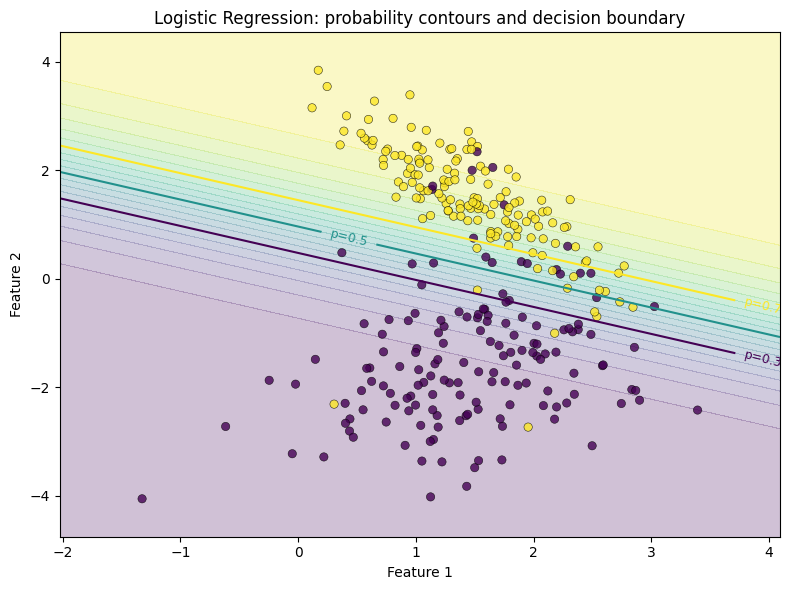

In [8]:
x_min, x_max = X_classification[:, 0].min() - 0.7, X_classification[:, 0].max() + 0.7
y_min, y_max = X_classification[:, 1].min() - 0.7, X_classification[:, 1].max() + 0.7
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid_points = np.column_stack([xx.ravel(), yy.ravel()])
grid_probabilities = logistic_pipeline.predict_proba(grid_points)[:, positive_class_index]
probability_surface = grid_probabilities.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, probability_surface, levels=20, alpha=0.25)
contours = plt.contour(xx, yy, probability_surface, levels=[0.3, 0.5, 0.7], linewidths=1.5)
plt.clabel(contours, inline=True, fontsize=9, fmt="p=%.1f")
plt.scatter(
    X_train_cls[:, 0], X_train_cls[:, 1],
    c=y_train_cls, edgecolor="black", linewidth=0.4, alpha=0.8
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression: probability contours and decision boundary")
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین: تمرین پایانی Logistic Regression</h3>
<ul><li>یک نمونه با احتمال‌های [۰٫۳،۰٫۷] داریم. برچسب آن در آستانه‌های ۰٫۵ و ۰٫۸ چیست؟</li><li>نشان بده اگر p=۰٫۸ باشد، log-odds مثبت است و مقدارش حدود ۱٫۳۸۶ است.</li><li>با تغییر Threshold در کد، تعداد برچسب‌های کلاس مثبت را گزارش کن.</li><li>اختیاری: با نگه‌داشتن مدل و تغییر Threshold، مرز تصمیم جدید را روی نمودار رسم کن.</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">مسئلهٔ کاربردی | آیا دستگاه صنعتی به بازبینی نیاز دارد؟</h3>

<p><strong>سناریو:</strong> یک کارخانه روی موتورهای خود دو حسگر دارد: دمای بدنه بر حسب درجهٔ سلسیوس و شدت لرزش بر حسب میلی‌متر بر ثانیه. هدف این است که پیش از بازرسی، احتمال «نیاز به بررسی فنی» را برای هر دستگاه تخمین بزنیم.</p>
<ul><li><code>temperature_c</code>: دمای دستگاه (°C)</li><li><code>vibration_mm_s</code>: شدت لرزش (mm/s)</li><li><code>needs_inspection</code>: برچسب ۰ (فعلاً بدون هشدار) یا ۱ (نیازمند بازبینی)</li></ul>
<p>این داده‌ها <strong>شبیه‌سازی‌شده‌اند</strong> و برای آموزش مفهوم ساخته شده‌اند؛ نه از یک کارخانهٔ واقعی و نه مناسب استفادهٔ ایمنی در محیط صنعتی.</p>
<p><strong>پیش از اجرای کد بپرس:</strong> به نظرتان افزایش دما یا لرزش احتمال خرابی را زیاد می‌کند یا کم؟ اگر مدل احتمال ۰٫۶ برگرداند، آیا حتماً دستگاه خراب است؟</p>

</div></div>

$$
P(y=1\mid T,V)=\sigma\!\left(\beta_0+\beta_1(T-75)+\beta_2(V-4)\right)
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">برداشت درست از مدل احتمالی</h3>
<p>در این آزمایش، <code>y=1</code> به معنی «ثبت وضعیت نیازمند بررسی فنی در دادهٔ شبیه‌سازی‌شده» است، نه اثبات قطعی خرابی. مدل باید از برچسب‌های آموزشی ضرایب را یاد بگیرد و روی دادهٔ آزمون عملکردش بررسی شود. یک احتمال بالا تنها تصمیم را هدایت می‌کند؛ جای بازرسی فنی را نمی‌گیرد.</p>
</div></div>

,temperature_c,vibration_mm_s,needs_inspection
0,69.275653,3.161749,0
1,80.646284,6.515976,1
2,57.140410,5.521173,0
3,93.353489,3.431424,0
4,85.021242,5.142900,1


Class balance: {0: 255, 1: 165}


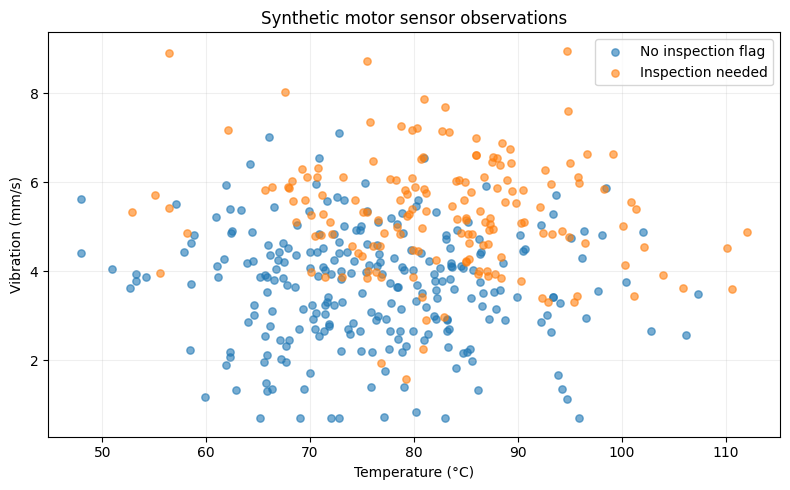

In [9]:
# Simulated sensor dataset: all measurements are synthetic.
rng_motor = np.random.default_rng(2026)
n_motor = 420
temperature_c = np.clip(rng_motor.normal(78, 11, n_motor), 48, 112)
vibration_mm_s = np.clip(
    rng_motor.normal(4.3, 1.5, n_motor) + 0.012 * (temperature_c - 78),
    0.7, 9.5
)
# The following unknown (to the learner) mechanism makes the labels probabilistic.
latent_score = -1.0 + 0.075 * (temperature_c - 75) + 0.78 * (vibration_mm_s - 4)
simulated_risk = 1 / (1 + np.exp(-latent_score))
needs_inspection = rng_motor.binomial(1, simulated_risk)
# needs_inspection  = simulated_risk > 0.5

motor_df = pd.DataFrame({
    "temperature_c": temperature_c,
    "vibration_mm_s": vibration_mm_s,
    "needs_inspection": needs_inspection
})
display(motor_df.head())
print("Class balance:", motor_df["needs_inspection"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(8, 5))
for label_value, title in [(0, "No inspection flag"), (1, "Inspection needed")]:
    subset = motor_df[motor_df["needs_inspection"] == label_value]
    ax.scatter(subset["temperature_c"], subset["vibration_mm_s"],
               alpha=0.6, s=28, label=title)
ax.set(xlabel="Temperature (°C)", ylabel="Vibration (mm/s)",
       title="Synthetic motor sensor observations")
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

In [11]:
# Define the problem: predict needs_inspection from two sensor readings.
motor_X = motor_df[["temperature_c", "vibration_mm_s"]].to_numpy()
motor_y = motor_df["needs_inspection"].to_numpy()
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    motor_X, motor_y, test_size=0.25, random_state=SEED, stratify=motor_y
)
motor_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=SEED))
])
motor_pipeline.fit(Xm_train, ym_train)
positive_ix_motor = np.flatnonzero(motor_pipeline.named_steps["logistic"].classes_ == 1)[0]
motor_p_test = motor_pipeline.predict_proba(Xm_test)[:, positive_ix_motor]

example_motors = np.array([[68., 2.0], [80., 4.5], [96., 7.0]])
example_prob = motor_pipeline.predict_proba(example_motors)[:, positive_ix_motor]
display(pd.DataFrame({
    "Temperature (°C)": example_motors[:,0],
    "Vibration (mm/s)": example_motors[:,1],
    "Estimated P(needs inspection)": np.round(example_prob, 3),
    "Flag at threshold=0.5": (example_prob >= 0.5).astype(int)
}))
print("Held-out test accuracy at threshold=0.5:",
      round(float(np.mean((motor_p_test >= 0.5) == ym_test)), 3))

,Temperature (°C),Vibration (mm/s),Estimated P(needs inspection),Flag at threshold=0.5
0,68.0,2.0,0.018,0
1,80.0,4.5,0.403,0
2,96.0,7.0,0.970,1


Held-out test accuracy at threshold=0.5: 0.743


In [13]:
 motor_pipeline.predict_proba(example_motors)

array([[0.98187843, 0.01812157],
       [0.59702995, 0.40297005],
       [0.0303737 , 0.9696263 ]])

,threshold,alerts,missed_flagged_cases,unnecessary_alerts
0,0.3,56,7,22
1,0.5,40,14,13
2,0.7,20,25,4


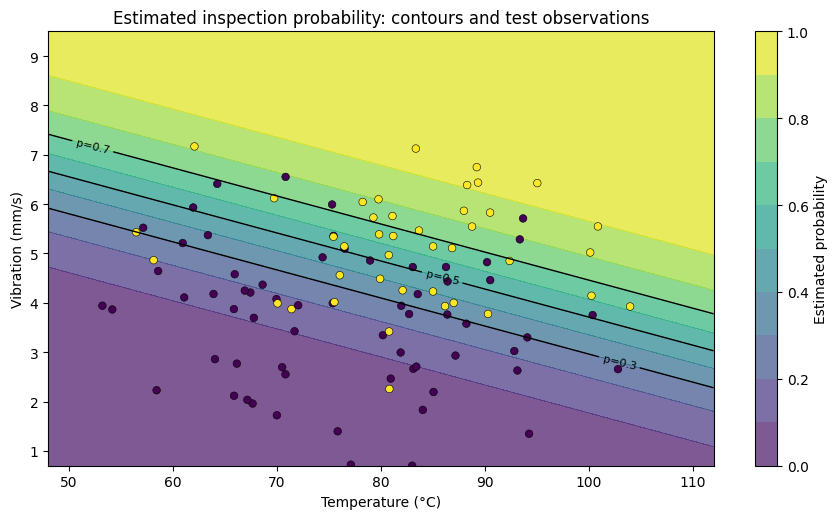

In [24]:
# Operational decision: a lower threshold increases alerts and can reduce misses.
operational_rows = []
for t in [0.30, 0.50, 0.70]:
    alerts = (motor_p_test >= t).astype(int)
    operational_rows.append({
        "threshold": t,
        "alerts": int(alerts.sum()),
        "missed_flagged_cases": int(np.sum((alerts == 0) & (ym_test == 1))),
        "unnecessary_alerts": int(np.sum((alerts == 1) & (ym_test == 0)))
    })
display(pd.DataFrame(operational_rows))

xx_motor, yy_motor = np.meshgrid(
    np.linspace(48, 112, 180), np.linspace(.7, 9.5, 190)
)
grid_motor = np.c_[xx_motor.ravel(), yy_motor.ravel()]
zz_motor = motor_pipeline.predict_proba(grid_motor)[:, positive_ix_motor].reshape(xx_motor.shape)
fig, ax = plt.subplots(figsize=(9, 5.3))
filled = ax.contourf(xx_motor, yy_motor, zz_motor, levels=np.linspace(0,1,11), alpha=.7)
lines = ax.contour(xx_motor, yy_motor, zz_motor, levels=[.3,.5,.7], colors='k', linewidths=1)
ax.clabel(lines, fmt="p=%.1f", fontsize=8)
ax.scatter(Xm_test[:,0], Xm_test[:,1], c=ym_test, edgecolors='black', linewidths=.4, s=30)
ax.set(xlabel="Temperature (°C)", ylabel="Vibration (mm/s)",
       title="Estimated inspection probability: contours and test observations")
fig.colorbar(filled, ax=ax, label="Estimated probability")
plt.tight_layout(); plt.show()

In [23]:
zz_motor

array([[0.00117106, 0.00119826, 0.00122609, ..., 0.06417664, 0.06557117,
        0.06699383],
       [0.00123431, 0.00126297, 0.0012923 , ..., 0.0674131 , 0.06887277,
        0.07036167],
       [0.00130097, 0.00133118, 0.00136209, ..., 0.07080042, 0.07232776,
        0.07388542],
       ...,
       [0.95687539, 0.95781409, 0.95873323, ..., 0.99923009, 0.99924757,
        0.99926466],
       [0.95899704, 0.95989149, 0.96076723, ..., 0.99926956, 0.99928615,
        0.99930236],
       [0.96101856, 0.96187067, 0.96270488, ..., 0.99930701, 0.99932274,
        0.99933813]], shape=(190, 180))

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">فعالیت تحلیلی | تصمیم‌گیری در تعمیر و نگهداری</h3>

<ol><li>اگر <strong>نادیده‌گرفتن یک خرابی واقعی</strong> پرهزینه‌تر از بازبینی اضافه باشد، Threshold را به کدام سمت تغییر می‌دهی؟ چرا؟</li>
<li>آیا <code>predict()</code> و <code>predict_proba()</code> معنای یکسانی دارند؟</li>
<li>نقاط نزدیک خط <code>p=0.5</code> چه تفاوتی با نقاط بسیار دور از این خط دارند؟</li>
<li>برای ارزیابی استفادهٔ واقعی از این مدل چه اطلاعاتی علاوه بر دما و لرزش لازم داریم؟</li></ol>
<p><strong>چالش:</strong> یک حسگر سوم مانند جریان الکتریکی یا ساعات کارکرد به مدل اضافه کن و تغییر عملکرد را بسنج؛ اما از برچسب یا متغیری که پس از بازرسی به دست می‌آید به‌عنوان ویژگی استفاده نکن.</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">تمرین از صفر (From Scratch) | Logistic Regression با NumPy</h2><p>سطح چالشی، پس از تکمیل مدل کتابخانه‌ای؛ این بخش می‌تواند به‌عنوان تکلیف خانه انجام شود.</p></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">مسیر فکرکردن قبل از کدنویسی</h3>
<p>در رگرسیون خطی، MSE را کمینه می‌کردیم. حالا خروجی ما <em>احتمال</em> است. برای کلاس ۱، احتمال نزدیک ۱ مطلوب است و برای کلاس ۰، احتمال نزدیک صفر. بنابراین از <strong>Binary Cross-Entropy</strong> استفاده می‌کنیم. سه قدم اصلی: ۱) امتیاز خطی و Sigmoid، ۲) محاسبهٔ گرادیان، ۳) به‌روزرسانی ضرایب با Gradient Descent.</p>
<p>برای جلوگیری از مشکل محاسباتی، می‌توان مقدار Loss را به‌شکل <code>np.logaddexp(0,z) - y*z</code> محاسبه کرد.</p>
</div></div>

$$
\mathcal L(\mathbf w,b)=-\frac1n\sum_{i=1}^{n}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]
$$

$$
p_i=\sigma(\mathbf x_i^T\mathbf w+b),\quad \nabla_{\mathbf w}\mathcal L=\frac1n X^T(\mathbf p-\mathbf y),\quad \frac{\partial\mathcal L}{\partial b}=\frac1n\sum_{i=1}^n(p_i-y_i)
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین عملی</h3>
<p>توابع <code>stable_sigmoid</code> و <code>fit_logistic_numpy</code> را بدون استفاده از <code>sklearn.linear_model</code> تکمیل کن. فقط NumPy مجاز است. ورودی را با مقیاس‌دهنده‌ای که <strong>فقط روی Train</strong> یاد گرفته شده استاندارد کن. نمودار Loss بر حسب گام و درصد تطابق پیش‌بینی‌ها با مدل کتابخانه‌ای را بررسی کن.</p>
</div></div>

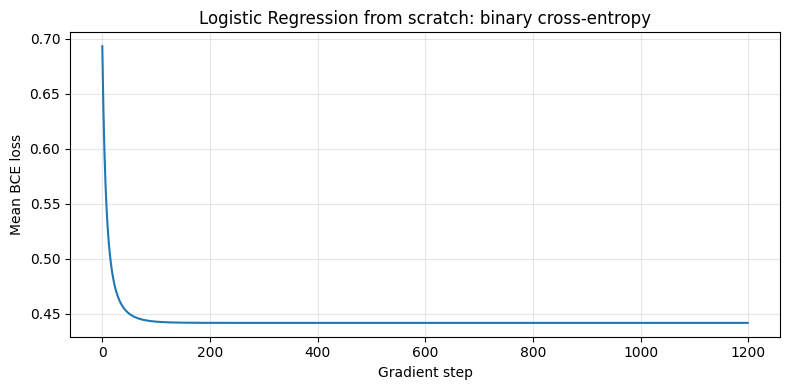

TODO: Implement Logistic Regression using only NumPy.


In [30]:
def stable_sigmoid(z):
    """TODO: Implement a numerically stable sigmoid with NumPy."""
    # TODO: Handle z >= 0 and z < 0 separately to avoid overflow.
    z = np.asarray(z, dtype=float)
    result = np.empty_like(z)

    positive = z >= 0
    negative = z < 0
    
    result[positive] = 1/(1 + np.exp(-z[positive]))
    result[negative] = np.exp(z[negative])/(1+np.exp(z[negative]))  
    return result


def fit_logistic_numpy(X, y, learning_rate=0.3, steps=1200):
    """TODO: Minimize BCE with batch gradient descent; return (w, b, history)."""
    n_samples,n_features=X.shape
    # TODO 1: Initialize coefficients and intercept.
    w=np.zeros(n_features)
    b=0.0
    history=[]

    # TODO 2: Compute z and probabilities.
    for step in range(steps):
        z= X @ w+b
        y_pred=stable_sigmoid(z)
        eps = 1e-15
        loss = -np.mean(
            y * np.log(y_pred + eps)
            + (1 - y) * np.log(1 - y_pred + eps)
        )
        history.append(loss)
    # TODO 3: Compute BCE and gradients; update the parameters.
        error=y_pred - y
        dw = (X.T @ error) / n_samples
        db= np.mean(error)
        w -= learning_rate*dw
        b -= learning_rate*db
    # TODO 4: Return w, b and a NumPy array of losses.

    return w,b,np.array(history)

# When the two TODO functions are ready, uncomment and complete:
scratch_motor_scaler = StandardScaler().fit(Xm_train)
Xm_train_std = scratch_motor_scaler.transform(Xm_train)
Xm_test_std = scratch_motor_scaler.transform(Xm_test)
result , bias , logistic_history = fit_logistic_numpy(Xm_train_std, ym_train)
# ...  # Plot loss and compare predictions with motor_pipeline.
plt.figure(figsize=(8,4)); plt.plot(logistic_history)
plt.title("Logistic Regression from scratch: binary cross-entropy")
plt.xlabel("Gradient step"); plt.ylabel("Mean BCE loss"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("TODO: Implement Logistic Regression using only NumPy.")

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">جلسهٔ دوم | شهود Regularization و Ridge Regression</h2><p>زمان: ۷۵ دقیقه — ابتدا شهود و ریاضی، سپس کدنویسی.</p></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">سؤال آغازین: آیا مدلِ دقیق‌تر روی آموزش، بهتر است؟</h3>
<p style="margin:6px 0;text-align:right;">دو دانش‌آموز را تصور کن: نفر اول پاسخ تمرین‌ها را حفظ می‌کند؛ نفر دوم رابطه و قاعده را یاد می‌گیرد. نفر اول شاید روی تمرین‌های تکراری عالی باشد ولی در آزمون جدید اشتباه کند. مدلِ بیش‌برازش‌کرده هم چنین رفتاری دارد.</p>
<p style="margin:6px 0;text-align:right;">در دادهٔ کم، ویژگی‌های زیاد یا مدل بسیار انعطاف‌پذیر، ضرایب می‌توانند برای توضیح نویز به مقدارهای بزرگ برسند. بزرگی ضرایب به‌تنهایی اثبات بیش‌برازش نیست، اما در مقیاس ویژگی یکسان می‌تواند نشانهٔ حساسیت بیش از حد باشد.</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">شهود مهم: علاوه بر خطا، هزینهٔ پیچیدگی هم بدهیم</h3>
<p style="margin:6px 0;text-align:right;">بدون Regularization به مدل می‌گوییم «فقط تا جای ممکن پیش‌بینی‌های آموزشی را دقیق کن». با Regularization می‌گوییم «هم خطا را کم کن، هم برای ضرایب بزرگ هزینه بپرداز».</p>
<p style="margin:6px 0;text-align:right;">این یک <strong>معامله (Trade-off)</strong> است. جریمهٔ خیلی کم ممکن است Overfitting را مهار نکند؛ جریمهٔ خیلی زیاد می‌تواند مدل را چنان محدود کند که Underfitting رخ دهد.</p>
<p style="margin:6px 0;text-align:right;">نکتهٔ دقیق: این روش معمولاً اندازهٔ ضرایب مدل را کنترل می‌کند؛ همیشه معادل «کاهش درجهٔ چندجمله‌ای» یا «کم کردن تعداد ویژگی‌ها» نیست.</p>
</div></div>

> فرمول عمومی برای رگرسیون با خطای مربعی:

$$
J(\mathbf w,b)=\underbrace{\frac{1}{2n}\sum_{i=1}^{n}(y_i-\mathbf x_i^T\mathbf w-b)^2}_{\text{Data fit}}+\underbrace{\lambda\,\Omega(\mathbf w)}_{\text{Complexity penalty}}
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">هر نماد در تابع هدف چه معنی دارد؟</h3>
<p style="margin:6px 0;text-align:right;"><strong>n</strong> تعداد نمونه‌هاست؛ <strong>w</strong> بردار ضرایب؛ <strong>b</strong> عرض از مبدأ؛ <strong>λ</strong> شدت جریمه (Hyperparameter که با Validation انتخاب می‌شود)؛ و <strong>Ω(w)</strong> نوع جریمه (مثلاً L1 یا L2).</p>
<p style="margin:6px 0;text-align:right;">پارامترهای w و b طی آموزش یاد گرفته می‌شوند؛ λ پیش از آموزش انتخاب می‌شود. معمولاً b را جریمه نمی‌کنیم، چون تغییر مبدأ خروجی نباید لزوماً «پیچیده» محسوب شود.</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">چرا L2 به نام Ridge شناخته می‌شود؟</h3>
<p style="margin:6px 0;text-align:right;">در Ridge، بزرگی همهٔ ضرایب (به‌جز Intercept) با مجموع مربع‌ها جریمه می‌شود. مربع وزن‌ها باعث می‌شود وزن‌های خیلی بزرگ به‌صورت نامتناسب هزینهٔ بیشتری داشته باشند.</p>
<p style="margin:6px 0;text-align:right;">اگر یک ضریب از ۲ به ۴ برسد، جریمهٔ L2 آن از ۴ به ۱۶ می‌رسد؛ یعنی چهار برابر. این خاصیت می‌تواند نوسان و حساسیت مدل را کنترل کند.</p>
</div></div>

$$
\Omega_{L2}(\mathbf w)=\|\mathbf w\|_2^2=\sum_{j=1}^{p}w_j^2
$$

$$
J_{\mathrm{Ridge}}(\mathbf w,b)=\frac{1}{2n}\|\mathbf y-X\mathbf w-b\mathbf 1\|_2^2+\frac{\lambda}{2}\|\mathbf w\|_2^2
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">برداشت ریاضی از اثر λ و مشتق Ridge</h3>
<p style="margin:6px 0;text-align:right;">در نسخهٔ با X و y مرکززدایی‌شده (بنابراین b لازم نیست) مشتق جملهٔ مربعی از ضرب ماتریسی به‌دست می‌آید. با صفر قرار دادن گرادیان، به معادلهٔ نرمالِ منظم‌شده می‌رسیم.</p>
<p style="margin:6px 0;text-align:right;">افزودن جملهٔ λI به XᵀX به‌ویژه وقتی ویژگی‌ها هم‌بسته یا ماتریس نزدیک تکین باشد پایداری محاسباتی ایجاد می‌کند. اما انتخاب λ خیلی بزرگ باعث نزدیک‌شدن وزن‌ها به صفر می‌شود.</p>
</div></div>

$$
\nabla_{\mathbf w}J=-\frac{1}{n}X^T(\mathbf y-X\mathbf w)+\lambda\mathbf w=\mathbf 0
$$

> این رابطه زمانی به شکل معکوس نوشته می‌شود که ماتریس وارون‌پذیر باشد؛ در کد از حل دستگاه خطی استفاده می‌کنیم، نه محاسبهٔ معکوس.

$$
(X^TX+n\lambda I)\mathbf w=X^T\mathbf y\qquad\Longrightarrow\qquad \hat{\mathbf w}=(X^TX+n\lambda I)^{-1}X^T\mathbf y
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">نکتهٔ مهم دربارهٔ Alpha در Scikit-learn</h3>
<p style="margin:6px 0;text-align:right;">ضریب Alpha در کتابخانه الزاماً با λ فرمولِ میانگین‌گیری‌شده برابر عددی نیست. Scikit-learn در Ridge از «مجموع مربعات خطا + α مجموع مربعات وزن» استفاده می‌کند؛ در فرمول بالا به علت تقسیم بر n، تطبیق α = nλ است.</p>
<p style="margin:6px 0;text-align:right;">در Lasso کتابخانه قرارداد دیگری برای مقیاس خطای داده دارد. بنابراین <strong>مقایسهٔ عدد Alpha بین دو کلاس بدون توجه به تعریف تابع هدف، اشتباه است</strong>.</p>
</div></div>

$$
\underbrace{\|\mathbf y-X\mathbf w\|_2^2+\alpha_{\mathrm{Ridge}}\|\mathbf w\|_2^2}_{\text{scikit-learn Ridge}}\quad\text{versus}\quad\frac{1}{2n}\|\mathbf y-X\mathbf w\|_2^2+\frac{\lambda}{2}\|\mathbf w\|_2^2
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">آزمایش ۱: روی داده‌های پُربعد چه رخ می‌دهد؟</h3>
<p style="margin:6px 0;text-align:right;">پیش‌بینی: وقتی تعداد ویژگی‌ها نسبت به نمونه‌ها زیاد است، مدل بدون جریمه می‌تواند ضرایب ناپایدارتری بیاموزد. در آزمایش زیر خطای آموزش و آزمون Linear Regression و Ridge را مقایسه می‌کنیم. عددهای خروجی وابسته به دادهٔ مصنوعی‌اند؛ اصل، تفاوت رفتار است.</p>
</div></div>

In [13]:
# Many features and relatively few training examples make overfitting easier to observe.
X_overfit, y_overfit = make_regression(
    n_samples=70,
    n_features=45,
    n_informative=6,
    noise=25,
    random_state=SEED
)

X_train_overfit, X_test_overfit, y_train_overfit, y_test_overfit = train_test_split(
    X_overfit, y_overfit, test_size=0.35, random_state=SEED
)

print("Training shape:", X_train_overfit.shape)
print("Test shape:", X_test_overfit.shape)
print("Number of features:", X_overfit.shape[1])

Training shape: (45, 45)
Test shape: (25, 45)
Number of features: 45


In [14]:
models_overfit = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge (alpha=10)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ])
}

rows = []
for model_name, model in models_overfit.items():
    model.fit(X_train_overfit, y_train_overfit)
    train_prediction = model.predict(X_train_overfit)
    test_prediction = model.predict(X_test_overfit)
    rows.append({
        "Model": model_name,
        "Train RMSE": mean_squared_error(y_train_overfit, train_prediction) ** 0.5,
        "Test RMSE": mean_squared_error(y_test_overfit, test_prediction) ** 0.5,
        "Train R2": r2_score(y_train_overfit, train_prediction),
        "Test R2": r2_score(y_test_overfit, test_prediction),
    })

overfit_results = pd.DataFrame(rows).round(3)
display(overfit_results)

,Model,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.00,190.949,1.000,-1.269
1,Ridge (alpha=10),29.97,53.708,0.955,0.820


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">فکر کن و پاسخ بده: تفسیر خروجی خطا</h3>
<ul><li>کدام مدل Train RMSE کمتری دارد؟</li><li>کدام مدل Test RMSE کمتری دارد؟</li><li>آیا چنین نتیجه‌ای برای هر دیتاست و هر Alpha تضمین می‌شود؟</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">آزمایش ۲: مسیر تغییر ضرایب Ridge</h3>
<p style="margin:6px 0;text-align:right;">در هر اجرای آزمایش تنها Alpha را تغییر می‌دهیم. با افزایش Alpha، ضرایب معمولاً به صفر نزدیک‌تر می‌شوند. خطای آموزش ممکن است افزایش پیدا کند، درحالی‌که خطای آزمون می‌تواند ابتدا کم و سپس زیاد شود؛ شکل دقیق داده‌وابسته است.</p>
<p style="margin:6px 0;text-align:right;"><strong>روش درست:</strong> Scaler تنها روی Train یاد گرفته می‌شود و روی Test صرفاً Transform اجرا می‌شود.</p>
</div></div>

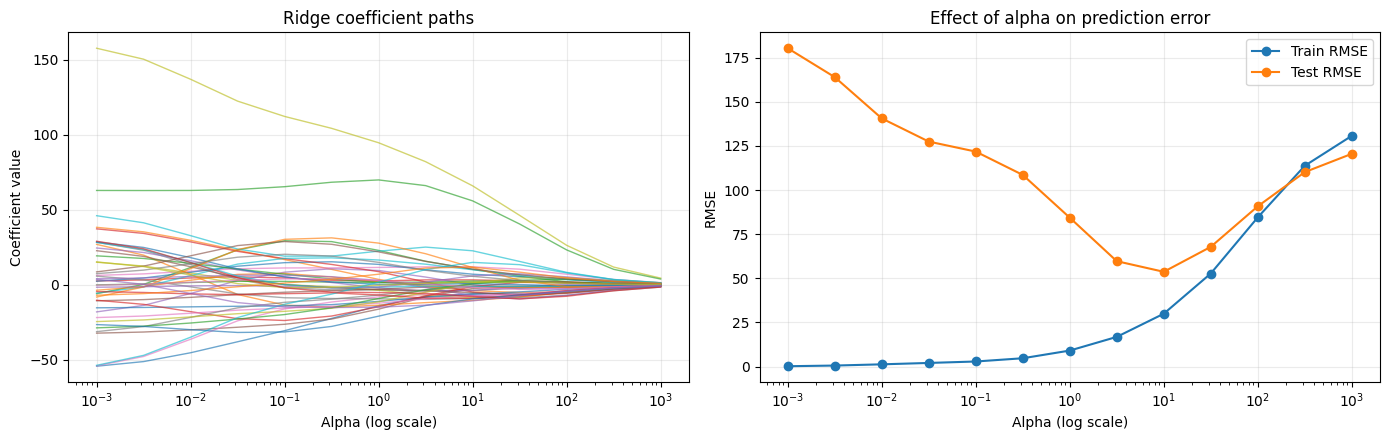

In [15]:
alpha_values = np.logspace(-3, 3, 13)
coefficient_paths = []
train_rmse_values = []
test_rmse_values = []

scaler_for_path = StandardScaler()
X_train_scaled = scaler_for_path.fit_transform(X_train_overfit)
X_test_scaled = scaler_for_path.transform(X_test_overfit)

for alpha in alpha_values:
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(X_train_scaled, y_train_overfit)
    coefficient_paths.append(ridge_model.coef_)
    train_rmse_values.append(mean_squared_error(y_train_overfit, ridge_model.predict(X_train_scaled)) ** 0.5)
    test_rmse_values.append(mean_squared_error(y_test_overfit, ridge_model.predict(X_test_scaled)) ** 0.5)

coefficient_paths = np.asarray(coefficient_paths)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for feature_index in range(coefficient_paths.shape[1]):
    axes[0].plot(alpha_values, coefficient_paths[:, feature_index], alpha=0.65, linewidth=1)
axes[0].set_xscale("log")
axes[0].set_title("Ridge coefficient paths")
axes[0].set_xlabel("Alpha (log scale)")
axes[0].set_ylabel("Coefficient value")
axes[0].grid(alpha=0.25)

axes[1].plot(alpha_values, train_rmse_values, marker="o", label="Train RMSE")
axes[1].plot(alpha_values, test_rmse_values, marker="o", label="Test RMSE")
axes[1].set_xscale("log")
axes[1].set_title("Effect of alpha on prediction error")
axes[1].set_xlabel("Alpha (log scale)")
axes[1].set_ylabel("RMSE")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">فکر کن و پاسخ بده: تحلیل نمودارهای Ridge</h3>
<ul><li>چه زمانی بیشترِ ضرایب از نظر قدرمطلق کوچک‌تر شده‌اند؟</li><li>آیا α بسیار بزرگ همیشه بهترین خطای آزمون را می‌دهد؟</li><li>چرا از Test برای انتخاب α نهایی استفاده نمی‌کنیم؟</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<p style="margin:6px 0;text-align:right;">در یک دقیقه توضیح بده فرق «بهتر fit شدن به Train» و «بهتر generalize شدن» چیست. سپس برای λ صفر و λ بسیار بزرگ، رفتار مورد انتظار Ridge را شرح بده.</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">تمرین از صفر (From Scratch) | حل Ridge با دستگاه خطی</h2><p>بعد از فهم مشتق و دستگاه نرمال، یک بار بدون Ridge آمادهٔ Scikit-learn مسئله را حل کن.</p></div>

$$
\hat{\mathbf w}_{\mathrm{Ridge}}=(X^TX+\alpha I)^{-1}X^T\mathbf y\quad\text{(notation only; solve numerically instead)}
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین محاسباتی | Ridge</h3>
<p>هدف پیاده‌سازی تابعی است که <strong>بدون گرفتن معکوس ماتریس</strong>، وزن‌های Ridge را با <code>np.linalg.solve</code> پیدا کند. برای ساده‌شدن تمرین، ویژگی‌ها استاندارد و هدف مرکزدهی می‌شود، بنابراین Intercept در دستگاه ظاهر نمی‌شود.</p><p>توجه: اینجا تعریف <code>alpha</code> را مطابق قرارداد <code>sklearn.Ridge</code>، یعنی <code>||y - Xw||² + alpha ||w||²</code> می‌گیریم؛ این همان ضریب λ با تعریف دارای <code>1/(2n)</code> نیست.</p>
</div></div>

In [16]:
def ridge_from_scratch(X, y, alpha):
    """TODO: Solve Ridge normal equations with np.linalg.solve."""
    # TODO: validate alpha, form X.T @ X + alpha * I and X.T @ y.
    # Do not call sklearn's Ridge or np.linalg.inv.
    return None

# TODO: compare coefficients with Ridge(alpha=5, fit_intercept=False),
# using X_train_scaled and a centered target vector.
print("TODO: Implement Ridge with NumPy linear algebra.")

TODO: Implement Ridge with NumPy linear algebra.


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">جلسهٔ سوم | Lasso، هندسهٔ L1/L2، انتخاب مدل و Tikhonov</h2><p>زمان: ۷۵ دقیقه — قیاس ریاضی، مشاهدهٔ نمودار، سپس آزمایش عملی.</p></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">مرور: دو راه برای کنترل ضرایب</h3>
<p style="margin:6px 0;text-align:right;">در جلسهٔ اول L2 را دیدیم: مربع ضرایب بزرگ مجازات سنگینی دارد. این جلسه می‌پرسیم: «اگر بخواهیم بعضی ویژگی‌ها به‌کلی کنار گذاشته شوند، چه جریمه‌ای مناسب است؟»</p>
<p style="margin:6px 0;text-align:right;">جریمهٔ L1، مجموع قدر مطلق ضرایب است. به علت گوشه‌های تیز ناحیهٔ مجاز L1، جواب بهینه می‌تواند روی یکی از محورهای مختصات قرار گیرد؛ یعنی یک یا چند ضریب دقیقاً صفر شود.</p>
</div></div>

$$
\Omega_{L1}(\mathbf w)=\|\mathbf w\|_1=\sum_{j=1}^{p}|w_j|
$$

$$
J_{\mathrm{Lasso}}(\mathbf w,b)=\frac{1}{2n}\|\mathbf y-X\mathbf w-b\mathbf 1\|_2^2+\alpha_{\mathrm{Lasso}}\|\mathbf w\|_1
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">L1 و L2 را با یک مثال عددی مقایسه کنیم</h3>
<p style="margin:6px 0;text-align:right;">برای بردار (۴،۰) داریم L1=۴ و L2-squared=۱۶. برای بردار (۲،۲) داریم L1=۴ و L2-squared=۸. در این دو مثال L1 هر دو بردار را یکسان جریمه می‌کند، اما L2 برای پخش‌شدن وزن‌ها جریمهٔ کمتری می‌دهد.</p>
<p style="margin:6px 0;text-align:right;">این مثال به‌تنهایی نتیجهٔ بهینه‌سازی Lasso را ثابت نمی‌کند؛ <strong>اثر صفرشدن ضرایب از تعامل هندسهٔ جریمه و سطح‌های تابع خطا ناشی می‌شود</strong>.</p>
</div></div>

$$
\begin{aligned}\|(4,0)\|_1&=4,&\|(4,0)\|_2^2&=16\\\|(2,2)\|_1&=4,&\|(2,2)\|_2^2&=8\end{aligned}
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">شهود مشتق: تفاوت رفتار اطراف صفر</h3>
<p style="margin:6px 0;text-align:right;">مشتق L2 برای هر وزن ۲w است؛ هرچه وزن کوچک‌تر شود، «نیروی» جریمه هم آرام‌تر می‌شود. در L1 مشتق در هر طرفِ صفر علامت ثابت دارد و در خود صفر مشتق معمولی ندارد؛ این گوشهٔ تیز می‌تواند جوابی دقیقاً با w=0 بسازد.</p>
<p style="margin:6px 0;text-align:right;">در بهینه‌سازی L1 از مفهوم <strong>Subgradient</strong> استفاده می‌شود: در صفر، مقدار مجاز مشتق تعمیم‌یافته بین منفی یک و مثبت یک است. این توضیح برای فهم صفرشدن دقیق مهم است ولی لازم نیست امروز روش حل کامل Lasso را مشتق بگیریم.</p>
</div></div>

$$
\frac{d}{dw}(w^2)=2w\qquad\quad \partial |w|=\begin{cases}\{+1\},&w>0\\\left[-1,1\right],&w=0\\\{-1\},&w<0\end{cases}
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">نمودار ۱: شکل جریمه برای یک وزن</h3>
<p style="margin:6px 0;text-align:right;">برای وزن‌های منفی و مثبت، L1 به شکل V است و L2-squared به شکل سهمی. در صفر، شکل V گوشه دارد و سهمی مشتق صفر. پیش از اجرا، حدس بزن کدام نمودار در |w| بزرگ سریع‌تر رشد می‌کند.</p>
</div></div>

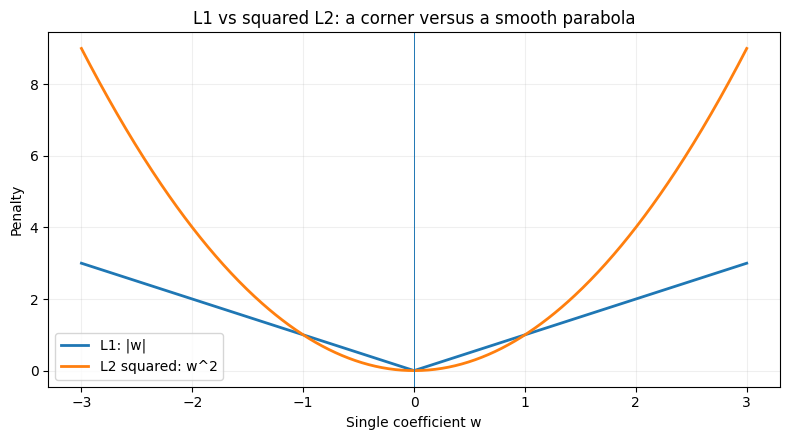

In [17]:
w_axis = np.linspace(-3, 3, 601)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(w_axis, np.abs(w_axis), label="L1: |w|", linewidth=2)
ax.plot(w_axis, w_axis**2, label="L2 squared: w^2", linewidth=2)
ax.axvline(0, linewidth=0.7)
ax.set_xlabel("Single coefficient w")
ax.set_ylabel("Penalty")
ax.set_title("L1 vs squared L2: a corner versus a smooth parabola")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">نمودار ۲: هندسهٔ L1 و L2 در فضای دو ضریب</h3>
<p style="margin:6px 0;text-align:right;">در دو بعد، مجموعهٔ نقاط با مجموع قدر مطلق ثابت، لوزی (Diamond) می‌سازد. مجموعهٔ نقاط با مجموع مربعات ثابت، دایره (Circle) می‌سازد. توجه کن که در نمودار دوم «L2-squared» را رسم می‌کنیم؛ مجموعه‌های تراز آن همچنان دایره‌اند.</p>
</div></div>

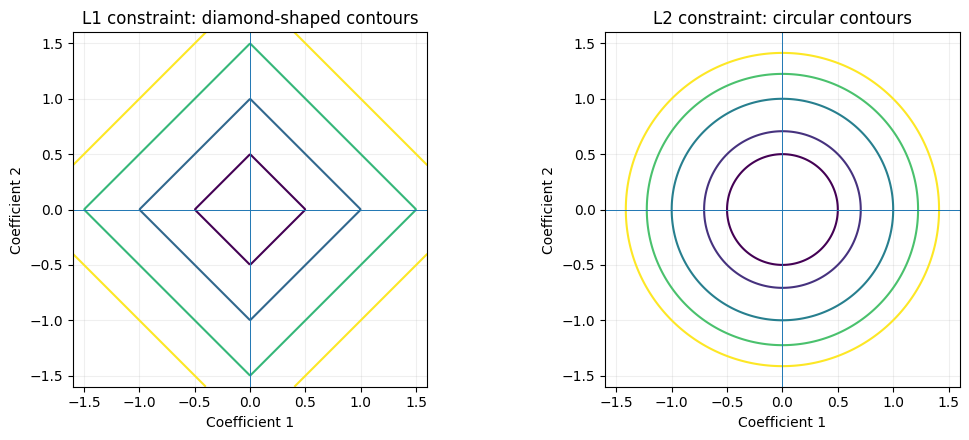

In [18]:
theta_1 = np.linspace(-1.6, 1.6, 400)
theta_2 = np.linspace(-1.6, 1.6, 400)
T1, T2 = np.meshgrid(theta_1, theta_2)
L1 = np.abs(T1) + np.abs(T2)
L2 = T1**2 + T2**2

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].contour(T1, T2, L1, levels=[0.5, 1.0, 1.5, 2.0], linewidths=1.5)
axes[0].set_title("L1 constraint: diamond-shaped contours")
axes[1].contour(T1, T2, L2, levels=[0.25, 0.5, 1.0, 1.5, 2.0], linewidths=1.5)
axes[1].set_title("L2 constraint: circular contours")
for ax in axes:
    ax.set_xlabel("Coefficient 1")
    ax.set_ylabel("Coefficient 2")
    ax.axhline(0, linewidth=0.7)
    ax.axvline(0, linewidth=0.7)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">چرا هندسه به انتخاب ویژگی مربوط می‌شود؟</h3>
<p style="margin:6px 0;text-align:right;">اگر یک تابع خطای مربعی را حول پاسخ بدون جریمه رسم کنیم، سطح‌های مقدار مساوی به شکل بیضی‌اند. بهینه‌سازی در ناحیهٔ قیدی زمانی متوقف می‌شود که بیضی‌های خطا به لوزی L1 یا دایرهٔ L2 برسند. گوشه‌های لوزی روی محورند؛ پس وزن صفر طبیعی‌تر رخ می‌دهد.</p>
<p style="margin:6px 0;text-align:right;">تأکید کن: این شکل فقط <strong>شهود هندسی</strong> است. ابعاد بیشتر، ضرایب هم‌بسته و انتخاب Alpha نتیجهٔ نهایی را تعیین می‌کنند.</p>
</div></div>

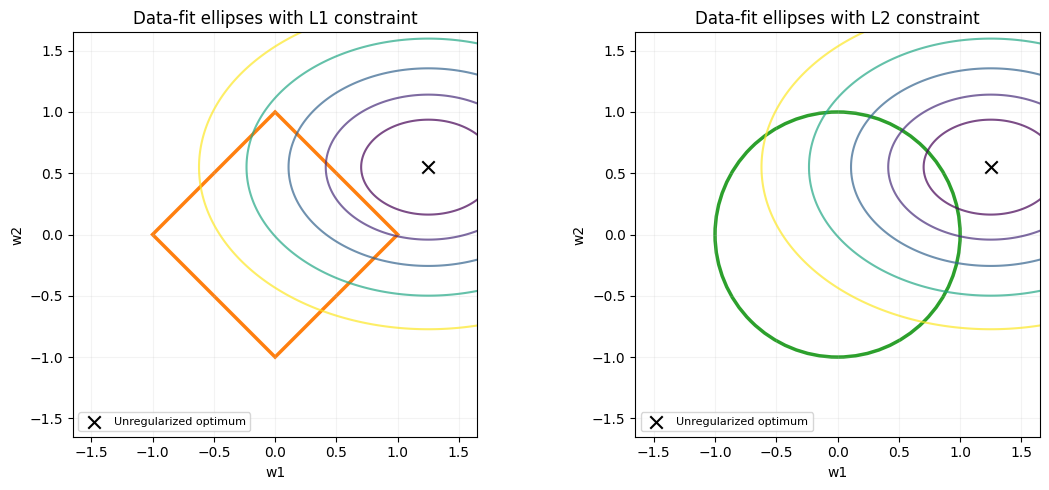

In [19]:
# Constrained-optimization intuition in 2D:
# A quadratic data-fit loss is compared with L1 and L2 feasible regions.
from matplotlib.patches import Polygon, Circle
u = np.linspace(-1.8, 1.8, 400)
W1, W2 = np.meshgrid(u, u)
loss_surface = (W1 - 1.25)**2 + 2.0 * (W2 - 0.55)**2
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
for ax, kind in zip(axes, ['L1', 'L2']):
    ax.contour(W1, W2, loss_surface, levels=[0.3,0.7,1.3,2.2,3.5], alpha=0.7)
    if kind == 'L1':
        shape = Polygon([(1,0),(0,1),(-1,0),(0,-1)], fill=False, linewidth=2.5,
                        edgecolor='tab:orange')
    else:
        shape = Circle((0,0),1,fill=False,linewidth=2.5,edgecolor='tab:green')
    ax.add_patch(shape)
    ax.scatter([1.25],[0.55],marker='x',s=80,color='black',label='Unregularized optimum')
    ax.set_xlim(-1.65,1.65); ax.set_ylim(-1.65,1.65)
    ax.set_aspect('equal'); ax.set_xlabel('w1'); ax.set_ylabel('w2')
    ax.set_title(f'Data-fit ellipses with {kind} constraint')
    ax.legend(loc='lower left',fontsize=8); ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">فکر کن و پاسخ بده: شهود هندسی</h3>
<ul><li>کدام شکل گوشه‌های واقع بر محور دارد؟</li><li>وقتی ضریب اول صفر باشد، مدل از آن ویژگی چگونه استفاده می‌کند؟</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">آزمایش ۳: Ridge و Lasso روی ویژگی‌های informative و نویزی</h3>
<p style="margin:6px 0;text-align:right;">برای ۲۴ ویژگی که فقط ۶ عدد از آن‌ها واقعاً اطلاعات پیش‌بینی دارند، سه مدل را مقایسه می‌کنیم. پیش‌بینی: Lasso با Alpha مناسب ممکن است برخی ضرایب را صفر کند، درحالی‌که Ridge معمولاً آن‌ها را کوچک ولی غیرصفر نگه می‌دارد.</p>
<p style="margin:6px 0;text-align:right;">این «انتخاب ویژگی» تفسیر ساده‌ای دارد؛ اما Lasso در حضور هم‌بستگی ممکن است یکی از چند ویژگی مشابه را انتخاب کند، پس صفر شدن وزن را نباید همیشه به معنای بی‌ارزش‌بودن واقعی یک ویژگی دانست.</p>
</div></div>

In [20]:
X_reg, y_reg = make_regression(
    n_samples=180,
    n_features=24,
    n_informative=6,
    noise=18,
    random_state=SEED
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=SEED
)

print("Training shape:", X_train_reg.shape)
print("Test shape:", X_test_reg.shape)
print("Total features:", X_reg.shape[1])

Training shape: (135, 24)
Test shape: (45, 24)
Total features: 24


In [21]:
comparison_models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=1.0, max_iter=20000))
    ])
}

comparison_rows = []
coefficient_table = {}

for model_name, model in comparison_models.items():
    model.fit(X_train_reg, y_train_reg)
    prediction = model.predict(X_test_reg)
    coefficients = model.named_steps["model"].coef_
    coefficient_table[model_name] = coefficients
    comparison_rows.append({
        "Model": model_name,
        "Test RMSE": mean_squared_error(y_test_reg, prediction) ** 0.5,
        "Test R2": r2_score(y_test_reg, prediction),
        "Number of near-zero coefficients": int(np.sum(np.abs(coefficients) < 1e-8))
    })

comparison_table = pd.DataFrame(comparison_rows).round(3)
display(comparison_table)

,Model,Test RMSE,Test R2,Number of near-zero coefficients
0,Linear Regression,20.511,0.968,0
1,Ridge,20.571,0.968,0
2,Lasso,19.007,0.972,8


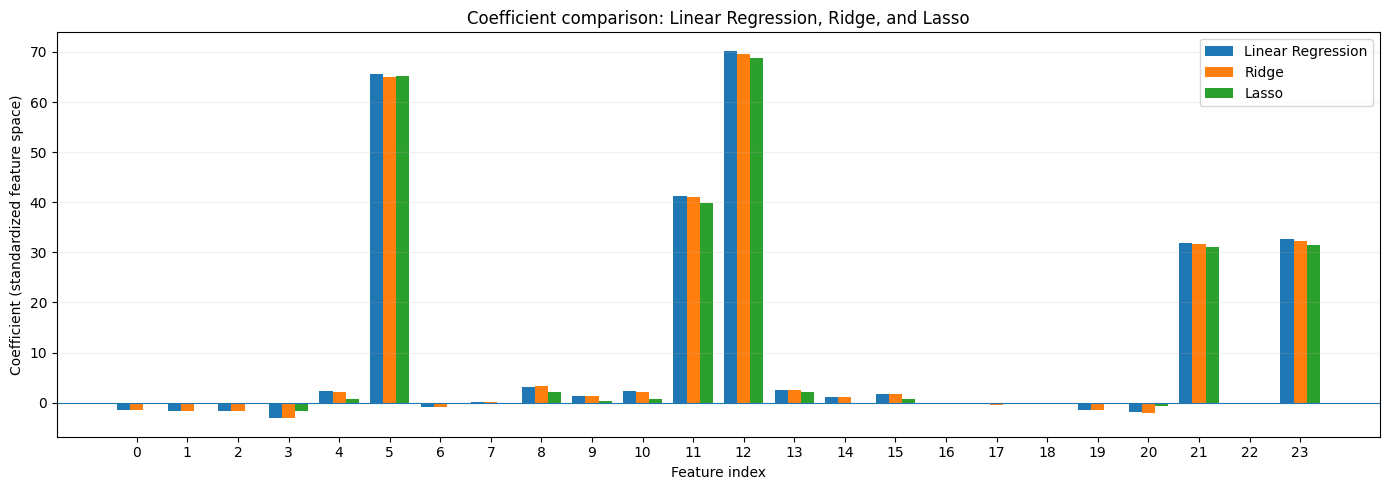

In [22]:
feature_positions = np.arange(X_reg.shape[1])
width = 0.26

plt.figure(figsize=(14, 5))
for offset, (model_name, coefficients) in zip([-width, 0, width], coefficient_table.items()):
    plt.bar(feature_positions + offset, coefficients, width=width, label=model_name)

plt.axhline(0, linewidth=0.8)
plt.xlabel("Feature index")
plt.ylabel("Coefficient (standardized feature space)")
plt.title("Coefficient comparison: Linear Regression, Ridge, and Lasso")
plt.xticks(feature_positions)
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">تمرین از صفر (From Scratch) | Lasso با Coordinate Descent</h2><p>الگوریتم پیشرفته‌تر؛ مناسب تمرین خانه یا دانش‌آموزان سریع‌تر.</p></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">ایدهٔ ریاضی و شهودی Coordinate Descent</h3>
<p>برخلاف Ridge، مشتقِ جریمهٔ قدرمطلق در صفر به‌شکل معمول تعریف نمی‌شود. راه عملی ساده این است که هر بار فقط یک ضریب را به‌روزرسانی کنیم و بقیه را ثابت نگه داریم. عملگر <strong>Soft Thresholding</strong> می‌تواند یک مقدار کوچک را دقیقاً صفر کند. ابتدا توضیح ریاضی، سپس کد قرار گرفته است.</p>
<p><strong>قرارداد تابع هدف:</strong> <code>(1/(2n)) ||y-Xw||² + alpha ||w||_1</code>، مطابق <code>sklearn.Lasso</code> برای دادهٔ مرکزدهی‌شده.</p>
</div></div>

$$
S_\alpha(z)=\operatorname{sign}(z)\max\bigl(|z|-\alpha,0\bigr)
$$

$$
\rho_j=\frac1n\mathbf x_j^T\bigl(\mathbf y-X\mathbf w+\mathbf x_j w_j\bigr),\qquad w_j\leftarrow\frac{S_\alpha(\rho_j)}{\frac1n\|\mathbf x_j\|_2^2}
$$

In [23]:
def soft_threshold(z, alpha):
    """TODO: Apply signed shrinkage; return exactly zero when |z| <= alpha."""
    return None


def lasso_coordinate_descent(X, y, alpha=1.0, max_iter=10000, tol=1e-8):
    """TODO: Implement cyclic coordinate descent for centered-target Lasso."""
    # TODO: zero initialization, residual updates, rho, soft-threshold, convergence.
    return None

# TODO: standardize training features; center y; compare with sklearn.Lasso.
# Check that uninformative coefficients can become exactly zero.
print("TODO: Implement Soft Thresholding and Lasso Coordinate Descent.")

TODO: Implement Soft Thresholding and Lasso Coordinate Descent.


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">آزمایش ۴: ویژگی‌های بسیار هم‌بسته</h3>
<p style="margin:6px 0;text-align:right;">گاهی دو ستون تقریباً یک نوع اطلاعات دارند. Ridge معمولاً اثر آن‌ها را بین چند وزن تقسیم می‌کند؛ Lasso ممکن است یکی را انتخاب و دیگری را حذف کند. نتیجه به نویز و مقدار Alpha وابسته است؛ هیچ قانون قطعی «همیشه این یکی» نداریم.</p>
</div></div>

In [24]:
rng = np.random.default_rng(SEED)
n_samples = 160
x_1 = rng.normal(size=n_samples)
x_2 = rng.normal(size=n_samples)

# x_1_copy is strongly correlated with x_1.
x_1_copy = x_1 + rng.normal(scale=0.05, size=n_samples)
X_correlated = np.column_stack([x_1, x_2, x_1_copy])
y_correlated = 4 * x_1 + 2 * x_2 + rng.normal(scale=0.5, size=n_samples)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_correlated, y_correlated, test_size=0.25, random_state=SEED
)

correlated_models = {
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=2.0))]),
    "Lasso": Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=0.15, max_iter=20000))])
}

for name, model in correlated_models.items():
    model.fit(Xc_train, yc_train)
    print(name, "coefficients:", np.round(model.named_steps["model"].coef_, 3))
    print(name, "test RMSE:", round(mean_squared_error(yc_test, model.predict(Xc_test)) ** 0.5, 3))

Ridge coefficients: [1.884 1.958 1.506]
Ridge test RMSE: 0.646
Lasso coefficients: [3.254 1.815 0.   ]
Lasso test RMSE: 0.643


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">چرا Scaling قبل از Regularization ضروری است؟</h3>
<p style="margin:6px 0;text-align:right;">فرض کن یک متغیر به متر و دیگری به میلی‌متر سنجیده می‌شود. برای همان اثر پیش‌بینی، ضریبِ متغیر با واحد بزرگ‌تر ممکن است کوچک‌تر باشد. اگر وزن‌ها را جریمه کنیم بدون اینکه مقیاس ورودی‌ها را یکسان کنیم، به‌صورت غیرمنصفانه با ویژگی‌ها رفتار کرده‌ایم.</p>
<p style="margin:6px 0;text-align:right;">در StandardScaler، میانگین هر ستون از آن کم می‌شود و بر انحراف معیارِ محاسبه‌شده روی Train تقسیم می‌شود. برای پیشگیری از Data Leakage، Scaler داخل Pipeline قرار می‌گیرد.</p>
</div></div>

$$
x_{ij}^{\mathrm{scaled}}=\frac{x_{ij}-\mu_j^{(\mathrm{train})}}{s_j^{(\mathrm{train})}}
$$

In [25]:
# Change the units of two features without changing the underlying information.
X_unbalanced = X_reg.copy()
X_unbalanced[:, 0] *= 1000
X_unbalanced[:, 1] *= 0.01

Xu_train, Xu_test, yu_train, yu_test = train_test_split(
    X_unbalanced, y_reg, test_size=0.25, random_state=SEED
)

ridge_without_scaling = Ridge(alpha=10.0).fit(Xu_train, yu_train)
ridge_with_scaling = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
]).fit(Xu_train, yu_train)

print("RMSE without scaling:", round(mean_squared_error(yu_test, ridge_without_scaling.predict(Xu_test)) ** 0.5, 3))
print("RMSE with scaling:", round(mean_squared_error(yu_test, ridge_with_scaling.predict(Xu_test)) ** 0.5, 3))

RMSE without scaling: 22.976
RMSE with scaling: 22.685


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">Hyperparameter Search: از آزمون و خطای دلخواه تا انتخاب منصفانه</h3>
<p style="margin:6px 0;text-align:right;">مقدار Alpha پارامتری نیست که مدل از داده به‌طور مستقیم در fit حساب کند. باید چند مقدار نامزد را روی دادهٔ آموزشی با Validation مقایسه کرد. برای هر نامزد، همان Pipeline شامل Scaling و مدل را ارزیابی می‌کنیم؛ سپس بهترین را روی کل Train بازآموزی می‌کنیم.</p>
<p style="margin:6px 0;text-align:right;">در این نوت‌بوک انتخاب نهایی براساس RMSE اعتبارسنجی است، نه Test RMSE. Test فقط در انتها برای گزارش عملکرد مدلِ منتخب استفاده می‌شود.</p>
</div></div>

In [26]:
cv_strategy = 5
alpha_grid = np.logspace(-3, 2, 12)

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=20000))
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=None
)

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"model__alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=None
)

ridge_search.fit(X_train_reg, y_train_reg)
lasso_search.fit(X_train_reg, y_train_reg)

search_rows = []
for name, search in [("Ridge", ridge_search), ("Lasso", lasso_search)]:
    test_prediction = search.predict(X_test_reg)
    search_rows.append({
        "Model": name,
        "Best alpha": search.best_params_["model__alpha"],
        "Best CV RMSE": -search.best_score_,
        "Test RMSE": mean_squared_error(y_test_reg, test_prediction) ** 0.5,
        "Test R2": r2_score(y_test_reg, test_prediction)
    })

display(pd.DataFrame(search_rows).round(3))

,Model,Best alpha,Best CV RMSE,Test RMSE,Test R2
0,Ridge,0.534,20.047,20.537,0.968
1,Lasso,1.520,18.566,19.044,0.972


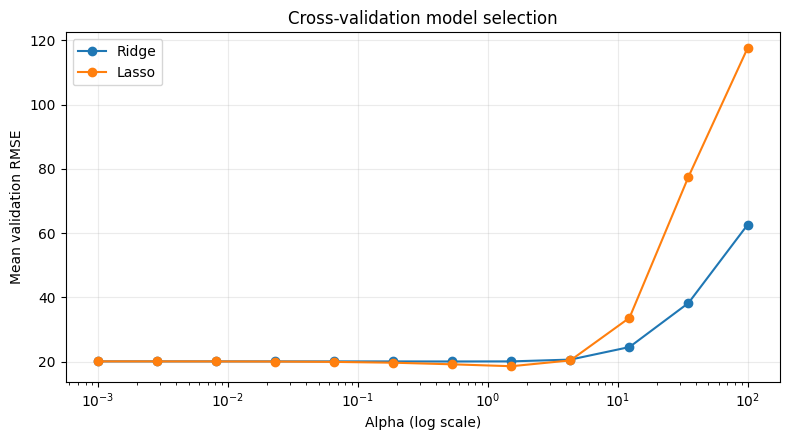

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, search in [("Ridge", ridge_search), ("Lasso", lasso_search)]:
    results = pd.DataFrame(search.cv_results_)
    mean_rmse = -results["mean_test_score"].to_numpy()
    tested_alpha = results["param_model__alpha"].astype(float).to_numpy()
    ax.plot(tested_alpha, mean_rmse, marker="o", label=name)

ax.set_xscale("log")
ax.set_xlabel("Alpha (log scale)")
ax.set_ylabel("Mean validation RMSE")
ax.set_title("Cross-validation model selection")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">فکر کن و پاسخ بده: انتخاب Alpha</h3>
<ul><li>کدام Alpha بهترین میانگین خطای Validation را دارد؟</li><li>چرا Test را وارد فرآیند جست‌وجو نمی‌کنیم؟</li><li>چرا مدل استانداردشده را داخل Pipeline می‌گذاریم؟</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">تمرین  | Regularization تیخونوف (Tikhonov)</h2><p>این بخش برای تمرین تحلیلی و یک آزمایش کوچک NumPy است؛ نمونه‌اش یک سیگنال ترتیبی است، نه ویژگی‌های بی‌ترتیب.</p></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تیخونوف چه تعمیمی نسبت به Ridge دارد؟</h3>
<p style="margin:6px 0;text-align:right;">در Ridge معمولی، خود وزن‌های مدل جریمه می‌شوند؛ یعنی ترجیح می‌دهیم وزن‌های کوچک باشند. در Tikhonov تعمیم‌یافته می‌توانیم به‌جای خود وزن‌ها، تبدیل خطی Lw را جریمه کنیم.</p>
<p style="margin:6px 0;text-align:right;">انتخاب L معنای «سادگی» را تعیین می‌کند. اگر L=I باشد همان جریمهٔ Ridge را داریم. اگر L ماتریس تفاضل مرتبهٔ اول باشد، مدل اختلاف مقدارهای متوالی را جریمه می‌کند؛ یعنی دنبال <strong>همواربودن</strong> سیگنال می‌گردد.</p>
<p style="margin:6px 0;text-align:right;">احتیاط: استفاده از ماتریس تفاضل روی ویژگی‌های کاملاً بی‌ترتیب لزوماً معنی ندارد؛ در مثال سیگنال زمانی، ترتیب طبیعی داریم.</p>
</div></div>

$$
\hat{\mathbf w}=\arg\min_{\mathbf w}\left[\|A\mathbf w-\mathbf y\|_2^2+\lambda\|L\mathbf w\|_2^2\right]
$$

> با مشتق‌گیری و مساوی صفر قرار دادن گرادیان، دستگاه نرمال تیخونوف به دست می‌آید.

$$
(A^TA+\lambda L^TL)\hat{\mathbf w}=A^T\mathbf y
$$

$$
L_{\mathrm{diff}}=\begin{bmatrix}-1&1&0&\cdots&0\\0&-1&1&\cdots&0\\\vdots&&\ddots&\ddots&\vdots\\0&\cdots&0&-1&1\end{bmatrix}\quad\Rightarrow\quad \|L_{\mathrm{diff}}\mathbf w\|_2^2=\sum_{j=1}^{m-1}(w_{j+1}-w_j)^2
$$

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین: Tikhonov — سطح ۱: تحلیل ریاضی</h3>
<ul><li>نشان دهید برای L=I تابع هدف به Ridge استاندارد در حالت بدون intercept تبدیل می‌شود.</li><li>برای بردار w=[2,2,2,2]، مقدار ||Dw||² و ||w||² را محاسبه کنید.</li><li>با مشتق‌گیری، فرم (AᵀA+λLᵀL)w=Aᵀy را به‌دست آورید.</li><li>در سیگنال زمانی توضیح دهید چرا L=D ممکن است از L=I مفیدتر باشد.</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">آزمایش تیخونوف: کمینه‌کردن نویز یک سیگنال</h3>
<p style="margin:6px 0;text-align:right;">یک سیگنال موجی صاف را در ۶۰ نقطه مشاهده می‌کنیم و به آن نویز می‌افزاییم. با A=I مجهول، خودِ سیگنال تمیزشده است. نسخهٔ Ridge مقدار نمونه‌ها را به صفر می‌کشد، اما تیخونوف تفاضلی تلاش می‌کند نمونه‌های مجاور به هم نزدیک شوند.</p>
</div></div>

In [28]:
# A self-contained, reproducible signal-denoising experiment.
rng_tikh = np.random.default_rng(23)
m = 60
time_axis = np.linspace(0, 2*np.pi, m)
true_signal = 1.5 + np.sin(time_axis)
noisy_signal = true_signal + rng_tikh.normal(0, 0.34, m)
A_signal = np.eye(m)
L_identity = np.eye(m)
L_difference = np.diff(np.eye(m), axis=0)
print('A shape:', A_signal.shape, 'D shape:', L_difference.shape)
print('D times a constant vector =', np.round(L_difference @ np.ones(m), 8)[:5])

A shape: (60, 60) D shape: (59, 60)
D times a constant vector = [0. 0. 0. 0. 0.]


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">فرمول محاسباتی: از معکوس‌گرفتن مستقیم پرهیز کن</h3>
<p style="margin:6px 0;text-align:right;">برای حل دستگاه از <code>np.linalg.solve</code> استفاده کن؛ نوشتن <code>np.linalg.inv(M) @ rhs</code> معمولاً نیاز نیست و از نظر پایداری/کارایی انتخاب ضعیف‌تری است. در این مثال به‌علت A=I، ماتریس دستگاه مثبت معین است.</p>
</div></div>

In [29]:
def tikhonov_solve(A, y, L, alpha):
    """Complete the generalized Tikhonov solver; avoid explicit matrix inversion."""
    # TODO 1: Build A.T @ A + alpha * (L.T @ L).
    # TODO 2: Build A.T @ y.
    # TODO 3: Solve the linear system with np.linalg.solve.
    return None

# TODO 4: Call your function for L_identity and L_difference.
# TODO 5: Plot original, noisy, Ridge and smoothness solutions.
# Hint: use A_signal, noisy_signal, alpha_tikh = 8.0.
print('Complete the Tikhonov exercise to draw the result.')

Complete the Tikhonov exercise to draw the result.


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین: Tikhonov — سطح ۲: تحلیل نتایج</h3>
<ul><li>برای α=۰ و α=۸ نتیجه را مقایسه کنید؛ چه اتفاقی برای سیگنال هموار می‌افتد؟</li><li>ثابت کنید L_difference @ ones(m) برابر صفر است. این چه معنایی برای ثابت‌ماندن میانگین دارد؟</li><li>اختیاری: ماتریس تفاضل دوم را بسازید و نتیجه را با تفاضل اول مقایسه کنید.</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">Exit Ticket جلسه دوم</h3>
<p style="margin:6px 0;text-align:right;">بدون دیدن کد پاسخ بده: چرا Ridge و Lasso نمودار مرز متفاوت دارند؟ چرا Lasso می‌تواند وزن صفر بدهد؟ در تیخونوف، انتخاب L دقیقاً چه چیزی را دربارهٔ «ساده بودن» مدل تعریف می‌کند؟</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">مرز این هفته و هفتهٔ ۱۵</h3>
<p>این هفته ایدهٔ <strong>Logistic Regression</strong>، احتمال، Threshold، Decision Boundary و یک مثال صنعتی را می‌بینیم؛ همچنین تمرین اختیاری آموزش از صفر را انجام می‌دهیم. در هفتهٔ ۱۵ تابع هزینه و Gradient Descent را عمیق‌تر مرور و معیارهای ارزیابی مثل Precision، Recall، F1 و ROC-AUC را کامل می‌کنیم.</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:1.8;color:inherit;"><h2 style="text-align:right;color:inherit;margin-bottom:5px;">جمع‌بندی، تمرین‌های مستقل و خودارزیابی</h2><p>پاسخ‌های مدرس در نسخهٔ دانش‌آموز نمایش داده نمی‌شوند.</p></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین: خودارزیابی مفهومی — سطح ۱</h3>
<ul><li>اگر λ بزرگ شود چرا ممکن است Underfitting رخ دهد؟</li><li>چرا بدون Scaling، ضرایب Ridge/Lasso قابل مقایسهٔ منصفانه نیستند؟</li><li>رابطهٔ دقیق Ridge و Lasso با مجموع مربع و قدر مطلق وزن‌ها چیست؟</li><li>چرا در طبقه‌بندی، Probability همان Class Label نیست؟</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین: تمرین عملی سطح ۲ — مقایسهٔ مدل‌ها</h3>
<ul><li>با استفاده از X_train_reg یک GridSearchCV برای Ridge یا Lasso بساز و بازهٔ Alpha را عوض کن.</li><li>براساس Validation بهترین Alpha را انتخاب کن؛ سپس فقط یک بار Test RMSE را گزارش کن.</li><li>ببین تعداد ضرایب دقیقاً صفرشده در Lasso چگونه با Alpha تغییر می‌کند.</li><li>نتیجه را با حداقل پنج جملهٔ تحلیلی توضیح بده.</li></ul>
</div></div>

In [30]:
# TODO: Test these Lasso alphas and count near-zero coefficients.
alpha_probe = [0.001, 0.01, 0.1, 1.0, 10.0]
zero_counts = []
# TODO: Fit a Pipeline(StandardScaler, Lasso) for each alpha.
# TODO: Append the number of nearly-zero coefficients.
print('Complete the exercise. Values:', zero_counts)

Complete the exercise. Values: []


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #8b5cf6;background:rgba(139,92,246,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تمرین: تمرین چالشی سطح ۳ — تیخونوف</h3>
<ul><li>تابع tikhonov_solve را در سلول تمرین کامل کن؛ شکل ماتریس‌های A، L و y را در نظر بگیر.</li><li>با L=I و L=D نمودارهای denoising را بساز و تفاوت را توضیح بده.</li><li>نشان بده اگر L=I و A=I باشد، جواب برابر y/(1+α) است.</li><li>پاسخ بده کدام جریمه برای مدل‌سازی یک سیگنال با سطح میانگین غیرصفر طبیعی‌تر است و چرا.</li></ul>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:12px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">چک‌لیست پایان هفته</h3>
<p style="margin:6px 0;text-align:right;">دلیل Regularization را می‌توانم شهودی بگویم؛ تابع هدف را درست می‌نویسم؛ تفاوت هندسی و ریاضی L1/L2 را می‌فهمم؛ می‌دانم چگونه Alpha را بدون نشت داده انتخاب کنم؛ تیخونوف را به‌صورت تعمیم Ridge می‌شناسم؛ و می‌توانم از خروجی Logistic Regression هم احتمال و هم برچسب بسازم.</p>
</div></div>